# Modelo de previsão se um cliente deixará o banco em breve.

# Contents <a id='back'></a>

* [Introdução](#intro)
* [Etapa 1. Visão geral dos dados](#data_review)
* [Etapa 2. Transformações dos dados](#tranforamation_data)
* [Etapa 3. Modelo](#model)
* [Conclusões](#end)

## Introdução <a id='intro'></a>

Os clientes do Beta Bank estão saindo: pouco a pouco, escapulindo todo mês. Os banqueiros descobriram que é mais barato manter os clientes existentes do que atrair novos.

Precisamos prever se um cliente vai deixar o banco em breve. Você tem os dados sobre o comportamento passado dos clientes e rescisões de contratos com o banco.

Construa um modelo com o valor máximo possível de F1. Para passar na revisão, você precisa de um F1-score de pelo menos 0,59 para o conjunto de dados de teste. 

Além disso, meça a métrica AUC-ROC e compare-a com o F1-score.

### Objetivo: 
- Como você preparou os dados para o treinamento? Você processou todos os tipos de características?
- Você explicou bem os passos de pré-processamento?
- Como você investigou o equilíbrio das classes?
- Você estruturou o modelo sem levar em conta o desequilíbrio de classes?
- Quais são suas descobertas relacionadas à tarefa em questão?
- Você dividiu corretamente os dados em conjuntos?
- Como você tem trabalhado com o desequilíbrio de classes?
- Você usou pelo menos duas técnicas para correção de desequilíbrio?
- Você executou o treinamento, validação e teste final do modelo corretamente?
- Qual é o seu F1-score?
- Você examinou os valores de AUC-ROC?




### Descrição de dados

- `Abra e examine o arquivo de dados. Caminho para o arquivo:`
/datasets/Churn.csv. Baixar o conjunto de dados

[Voltar ao Índice](#back)

## Etapa 1. Visão geral dos dados <a id='data_review'></a>

Carregue os dados das consultas, explore-os e carregue bibliotecas que você acredita que são necessárias para o projeto.

In [1]:
# Bibliotecas para manipulação e análise de dados
import pandas as pd  # Pandas é utilizado para manipulação de dados e estruturas de dados
import numpy as np   # NumPy é utilizado para operações numéricas e manipulação de arrays

# Bibliotecas para visualização de dados
import matplotlib.pyplot as plt  # Matplotlib é utilizado para criar gráficos e visualizações

# Bibliotecas para estatísticas e testes
from scipy import stats as st  # SciPy oferece funções estatísticas e de teste

# Bibliotecas para aprendizado de máquina
from sklearn.model_selection import train_test_split  # Para dividir os dados em conjuntos de treino e teste
from sklearn.tree import DecisionTreeClassifier  # Classificador de árvore de decisão
from sklearn.ensemble import RandomForestClassifier  # Classificador de floresta aleatória
from sklearn.linear_model import LogisticRegression  # Regressão logística

# Bibliotecas para avaliação de modelos
from sklearn.metrics import accuracy_score  # Para calcular a acurácia do modelo
from sklearn.metrics import confusion_matrix  # Para criar a matriz de confusão
from sklearn.metrics import recall_score  # Para calcular a sensibilidade (recall)
from sklearn.metrics import precision_score  # Para calcular a precisão
from sklearn.metrics import roc_auc_score  # Para calcular a área sob a curva ROC

# Biblioteca para codificação de variáveis categóricas
from sklearn.preprocessing import OrdinalEncoder  # Para codificar variáveis categóricas em números

## Carregue os Dados

In [2]:
# Carregue o arquivo com os dados em um DataFrame
df = pd.read_csv('Churn.csv')  # Coloque o arquivo na mesma pasta do notebook

In [3]:
# Vamos ver quantas linhas e colunas nosso conjunto de dados tem
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), str(3)
memory usage: 1.2 MB


In [4]:
# vamos exibir as primeiras 10 linhas
df.head(10)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0
5,6,15574012,Chu,645,Spain,Male,44,8.0,113755.78,2,1,0,149756.71,1
6,7,15592531,Bartlett,822,France,Male,50,7.0,0.00,2,1,1,10062.80,0
7,8,15656148,Obinna,376,Germany,Female,29,4.0,115046.74,4,1,0,119346.88,1
8,9,15792365,He,501,France,Male,44,4.0,142051.07,2,0,1,74940.50,0
9,10,15592389,H?,684,France,Male,27,2.0,134603.88,1,1,1,71725.73,0


## Explore os dados iniciais

**Descrição dos dados**
- `RowNumber` - (índice das strings de dados)
- `CustomerId` - (identificador exclusivo do cliente)
- `Surname` - (sobrenome)
- `CreditScore` - (pontuação de crédito)
- `Geography` - (país de residência)
- `Gender` - (gênero)
- `Age` - (idade)
- `Tenure` - (tempo de serviço para o cliente)
- `Balance` - (saldo da conta)
- `NumOfProducts` - (número de produtos bancários usados pelo cliente)
- `HasCrCard` - (cliente possui cartão de crédito (1 - sim; 0 - não))
- `IsActiveMember` - (cliente ativo (1 - sim; 0 - não))
- `EstimatedSalary` - (salário estimado `сalls` - (número de chamadas))
- `Exited` - (o cliente saiu (1 - sim; 0 - não))

[Voltar ao Índice](#back)


### Duplicatas <a id='duplicates'></a>
Encontrando de duplicatas óbvias na tabela:

In [5]:
# Verificar Valores Duplicados
df.duplicated().sum()

np.int64(0)

### Valores ausentes <a id='missing_values'></a>

In [6]:
# Verificar Valores Ausentes
df.isna().sum()

RowNumber            0
CustomerId           0
Surname              0
CreditScore          0
Geography            0
Gender               0
Age                  0
Tenure             909
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64

In [7]:
(df.isnull().sum() / df.shape[0]) * 100

RowNumber          0.00
CustomerId         0.00
Surname            0.00
CreditScore        0.00
Geography          0.00
Gender             0.00
Age                0.00
Tenure             9.09
Balance            0.00
NumOfProducts      0.00
HasCrCard          0.00
IsActiveMember     0.00
EstimatedSalary    0.00
Exited             0.00
dtype: float64

Podemos observar que 9.09% dos nossos dados na coluna 'Tenure' estão faltantes, e não há duplicatas.Mas o nome das colunas não estão de acordo com as regras da boa prática de estilo, pois isso, iremos renomear esses nomes e verificar se há dados inconsistentes.

[Voltar ao Índice](#back)

## Etapa 2. Transformação de dados <a id='tranforamation_data'></a>
Vamos examinar cada coluna para ver quais problemas podemos ter nelas.

In [8]:
df['CustomerId'].sort_values()

1287    15565701
4198    15565706
7090    15565714
2020    15565779
3697    15565796
          ...   
3411    15815628
8271    15815645
8088    15815656
1762    15815660
5502    15815690
Name: CustomerId, Length: 10000, dtype: int64

In [9]:
df['Surname'].sort_values()

3271     Abazu
5109     Abazu
841      Abbie
2537    Abbott
2988    Abbott
         ...  
1030      Zuev
586      Zuyev
6973     Zuyev
6385    Zuyeva
7739    Zuyeva
Name: Surname, Length: 10000, dtype: str

In [10]:
df['CreditScore'].describe()

count    10000.000000
mean       650.528800
std         96.653299
min        350.000000
25%        584.000000
50%        652.000000
75%        718.000000
max        850.000000
Name: CreditScore, dtype: float64

In [11]:
df['Geography'].sort_values().unique()

<ArrowStringArray>
['France', 'Germany', 'Spain']
Length: 3, dtype: str

In [12]:
df['Gender'].sort_values().unique()

<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

In [13]:
df['Age'].describe()

count    10000.000000
mean        38.921800
std         10.487806
min         18.000000
25%         32.000000
50%         37.000000
75%         44.000000
max         92.000000
Name: Age, dtype: float64

In [14]:
df['Tenure'].sort_values().unique()

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., nan])

In [15]:
df['Balance'].describe()

count     10000.000000
mean      76485.889288
std       62397.405202
min           0.000000
25%           0.000000
50%       97198.540000
75%      127644.240000
max      250898.090000
Name: Balance, dtype: float64

In [16]:
df['NumOfProducts'].sort_values().unique()

array([1, 2, 3, 4])

In [17]:
df['HasCrCard'].sort_values().unique()

array([0, 1])

In [18]:
df['IsActiveMember'].sort_values().unique()

array([0, 1])

In [19]:
df['EstimatedSalary'].describe()

count     10000.000000
mean     100090.239881
std       57510.492818
min          11.580000
25%       51002.110000
50%      100193.915000
75%      149388.247500
max      199992.480000
Name: EstimatedSalary, dtype: float64

In [20]:
df['Exited'].sort_values().unique()

array([0, 1])

### Conclusões intermediárias <a id='data_preprocessing_conclusions_intermediary'></a>

Não há valores deproporcionais, nessa questão está tudo coerente.

[Voltar ao Índice](#back)


## Etapa 3. Transformação de dados <a id='tranforamation_data'>

In [21]:
# a lista dos nomes das colunas na tabela df
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [22]:
# renomeando colunas
df = df.rename(str.lower, axis='columns')

In [23]:
# a lista dos nomes das colunas na tabela df
df.columns

Index(['rownumber', 'customerid', 'surname', 'creditscore', 'geography',
       'gender', 'age', 'tenure', 'balance', 'numofproducts', 'hascrcard',
       'isactivemember', 'estimatedsalary', 'exited'],
      dtype='str')

### Preenchendo valores ausentes na coluna 'tenure'

In [24]:
# Vejamos a tabela filtrada com valores ausentes na primeira coluna com dados ausentes
df[df['tenure'].isna()].head(50)

,rownumber,customerid,surname,creditscore,geography,gender,age,tenure,balance,numofproducts,hascrcard,isactivemember,estimatedsalary,exited
30,31,15589475,Azikiwe,591,Spain,Female,39,NaN,0.00,3,1,0,140469.38,1
48,49,15766205,Yin,550,Germany,Male,38,NaN,103391.38,1,0,1,90878.13,0
51,52,15768193,Trevisani,585,Germany,Male,36,NaN,146050.97,2,0,0,86424.57,0
53,54,15702298,Parkhill,655,Germany,Male,41,NaN,125561.97,1,0,0,164040.94,1
60,61,15651280,Hunter,742,Germany,Male,35,NaN,136857.00,1,0,0,84509.57,0
82,83,15641732,Mills,543,France,Female,36,NaN,0.00,2,0,0,26019.59,0
85,86,15805254,Ndukaku,652,Spain,Female,75,NaN,0.00,2,1,1,114675.75,0
94,95,15676966,Capon,730,Spain,Male,42,NaN,0.00,2,0,1,85982.47,0
99,100,15633059,Fanucci,413,France,Male,34,NaN,0.00,2,0,0,6534.18,0
111,112,15665790,Rowntree,538,Germany,Male,39,NaN,108055.10,2,1,0,27231.26,0


Não há indicios que podemos substituir esses valores faltantes dessa coluna com base nas outras,segue muito aleatorio, por isso substituiremos com valor de 0.

In [25]:
#Substituindo valores faltantes vcom 0
df['tenure'].fillna(0, inplace = True)

/tmp/ipykernel_304/1050798341.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['tenure'].fillna(0, inplace = True)


0        2.0
1        1.0
2        8.0
3        1.0
4        2.0
        ... 
9995     5.0
9996    10.0
9997     7.0
9998     3.0
9999     0.0
Name: tenure, Length: 10000, dtype: float64

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   rownumber        10000 non-null  int64  
 1   customerid       10000 non-null  int64  
 2   surname          10000 non-null  str    
 3   creditscore      10000 non-null  int64  
 4   geography        10000 non-null  str    
 5   gender           10000 non-null  str    
 6   age              10000 non-null  int64  
 7   tenure           9091 non-null   float64
 8   balance          10000 non-null  float64
 9   numofproducts    10000 non-null  int64  
 10  hascrcard        10000 non-null  int64  
 11  isactivemember   10000 non-null  int64  
 12  estimatedsalary  10000 non-null  float64
 13  exited           10000 non-null  int64  
dtypes: float64(3), int64(8), str(3)
memory usage: 1.2 MB


Concluimos os pré-processamento de dados, não há mais valores ausentes, duplicados ou tipo de dados errado.

[Voltar ao Índice](#back)

## Etapa 3. Modelo <a id='model'></a>

In [27]:
#Transformando Variaveis categoricas em variáveis numéricas
df_gender = pd.get_dummies(df['gender']).reset_index()
df_geography = pd.get_dummies(df['geography']).reset_index()

In [28]:
# Realiza a junção (merge) dos DataFrames df_gender e df_geography
# Utiliza a junção do tipo 'left', o que significa que todas as linhas do df_gender serão mantidas
# e as correspondências do df_geography serão adicionadas onde houver correspondência na coluna 'index'
df_index = pd.merge(df_gender, df_geography, how='left', on='index')

In [29]:
df_index

,index,Female,Male,France,Germany,Spain
0,0,True,False,True,False,False
1,1,True,False,False,False,True
2,2,True,False,True,False,False
3,3,True,False,True,False,False
4,4,True,False,False,False,True
...,...,...,...,...,...,...
9995,9995,False,True,True,False,False
9996,9996,False,True,True,False,False
9997,9997,True,False,True,False,False
9998,9998,False,True,False,True,False


In [30]:
# Remove as colunas 'gender' e 'geography' do DataFrame df
# O parâmetro axis=1 indica que as colunas estão sendo removidas (em oposição a linhas)
# Após a remoção, o índice do DataFrame é redefinido com reset_index()
df_ohe = df.drop(['gender', 'geography'], axis=1).reset_index()

In [31]:
df_final = pd.merge(df_ohe, df_index, how = 'left', on = 'index')

In [32]:
df_final

,index,rownumber,customerid,surname,creditscore,age,tenure,balance,numofproducts,hascrcard,isactivemember,estimatedsalary,exited,Female,Male,France,Germany,Spain
0,0,1,15634602,Hargrave,619,42,2.0,0.00,1,1,1,101348.88,1,True,False,True,False,False
1,1,2,15647311,Hill,608,41,1.0,83807.86,1,0,1,112542.58,0,True,False,False,False,True
2,2,3,15619304,Onio,502,42,8.0,159660.80,3,1,0,113931.57,1,True,False,True,False,False
3,3,4,15701354,Boni,699,39,1.0,0.00,2,0,0,93826.63,0,True,False,True,False,False
4,4,5,15737888,Mitchell,850,43,2.0,125510.82,1,1,1,79084.10,0,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,9996,15606229,Obijiaku,771,39,5.0,0.00,2,1,0,96270.64,0,False,True,True,False,False
9996,9996,9997,15569892,Johnstone,516,35,10.0,57369.61,1,1,1,101699.77,0,False,True,True,False,False
9997,9997,9998,15584532,Liu,709,36,7.0,0.00,1,0,1,42085.58,1,True,False,True,False,False
9998,9998,9999,15682355,Sabbatini,772,42,3.0,75075.31,2,1,0,92888.52,1,False,True,False,True,False


In [33]:
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   index            10000 non-null  int64  
 1   rownumber        10000 non-null  int64  
 2   customerid       10000 non-null  int64  
 3   surname          10000 non-null  str    
 4   creditscore      10000 non-null  int64  
 5   age              10000 non-null  int64  
 6   tenure           9091 non-null   float64
 7   balance          10000 non-null  float64
 8   numofproducts    10000 non-null  int64  
 9   hascrcard        10000 non-null  int64  
 10  isactivemember   10000 non-null  int64  
 11  estimatedsalary  10000 non-null  float64
 12  exited           10000 non-null  int64  
 13  Female           10000 non-null  bool   
 14  Male             10000 non-null  bool   
 15  France           10000 non-null  bool   
 16  Germany          10000 non-null  bool   
 17  Spain            10000 n

In [34]:
# Divide o DataFrame df_final em dois conjuntos: df_train_valid e df_test
# 20% dos dados são reservados para o conjunto de teste (df_test)
# random_state=12345 garante que a divisão seja reprodutível
# stratify=df_final['exited'] assegura que a proporção da variável 'exited' seja mantida em ambos os conjuntos
df_train_valid, df_test = train_test_split(df_final, test_size=0.2, random_state=12345, stratify=df_final['exited'])

# Divide o DataFrame df_train_valid em dois conjuntos: df_train e df_valid
# 25% dos dados de df_train_valid são reservados para o conjunto de validação (df_valid)
# Isso resulta em 60% dos dados originais para treino e 20% para validação
# random_state=12345 garante que a divisão seja reprodutível
# stratify=df_train_valid['exited'] assegura que a proporção da variável 'exited' seja mantida em ambos os conjuntos
df_train, df_valid = train_test_split(df_train_valid, test_size=0.25, random_state=12345, stratify=df_train_valid['exited'])


In [35]:
# Remove colunas desnecessárias do DataFrame df_train para criar o conjunto de características (features)
# As colunas removidas são 'index', 'surname', 'rownumber', 'customerid' e 'exited'
# O resultado é armazenado em features_train
features_train = df_train.drop(['index', 'surname', 'rownumber', 'customerid', 'exited'], axis=1)

# Armazena a coluna 'exited' do DataFrame df_train como o alvo (target) para o modelo de treino
target_train = df_train['exited']

# Repete o processo para o conjunto de validação (df_valid)
# Remove colunas desnecessárias e armazena as características em features_valid
features_valid = df_valid.drop(['index', 'surname', 'rownumber', 'customerid', 'exited'], axis=1)

# Armazena a coluna 'exited' do DataFrame df_valid como o alvo (target) para o modelo de validação
target_valid = df_valid['exited']

# Repete o processo para o conjunto de teste (df_test)
# Remove colunas desnecessárias e armazena as características em features_test
features_test = df_test.drop(['index', 'surname', 'rownumber', 'customerid', 'exited'], axis=1)

# Armazena a coluna 'exited' do DataFrame df_test como o alvo (target) para o modelo de teste
target_test = df_test['exited']


## Melhorando o modelo

A meta do projeto é **F1 de pelo menos 0,59** no conjunto de teste. Por isso, todos os ajustes abaixo são escolhidos pelo **F1 no conjunto de validação**, e não pela acurácia: com cerca de 20% de clientes que saem, um modelo que nunca prevê a saída já teria 80% de acurácia e seria inútil.

In [36]:
from sklearn.metrics import f1_score, classification_report
from sklearn.utils import shuffle

# Árvore de decisão: F1 na validação para cada profundidade
for depth in range(2, 13, 2):
    modelo = DecisionTreeClassifier(random_state=12345, max_depth=depth).fit(features_train, target_train)
    print(f"max_depth = {depth:2d} | F1 na validação = {f1_score(target_valid, modelo.predict(features_valid)):.3f}")

max_depth =  2 | F1 na validação = 0.515


max_depth =  4 | F1 na validação = 0.517
max_depth =  6 | F1 na validação = 0.530


max_depth =  8 | F1 na validação = 0.580
max_depth = 10 | F1 na validação = 0.535


max_depth = 12 | F1 na validação = 0.535


In [37]:
# Floresta aleatória: busca da melhor combinação de profundidade e número de árvores, pelo F1 na validação
resultados_rf = []
for depth in [6, 8, 10, 12]:
    for est in [50, 100, 200]:
        modelo = RandomForestClassifier(random_state=12345, max_depth=depth, n_estimators=est, n_jobs=-1)
        modelo.fit(features_train, target_train)
        resultados_rf.append({"max_depth": depth, "n_estimators": est,
                              "F1": f1_score(target_valid, modelo.predict(features_valid))})
resultados_rf = pd.DataFrame(resultados_rf).sort_values("F1", ascending=False)
melhor = resultados_rf.iloc[0]
MAX_DEPTH, N_ESTIMATORS = int(melhor["max_depth"]), int(melhor["n_estimators"])
print(f"Melhor floresta: max_depth = {MAX_DEPTH}, n_estimators = {N_ESTIMATORS}, F1 = {melhor['F1']:.3f}")
resultados_rf.head()

Melhor floresta: max_depth = 12, n_estimators = 50, F1 = 0.555


,max_depth,n_estimators,F1
9,12,50,0.554839
10,12,100,0.546926
11,12,200,0.544262
6,10,50,0.521595
8,10,200,0.515254


A árvore de decisão chega a F1 de 0,58 com profundidade 8, e a melhor floresta aleatória sem balanceamento, a 0,55 (profundidade 12, 50 árvores). Os dois ainda ficam abaixo da meta, porque identificam poucos dos clientes que saem.

[Voltar ao Índice](#back)

## Valor de F1 sem Balanceamento de Classe

In [38]:
modelo_sem_balanceamento = RandomForestClassifier(random_state=12345, max_depth=MAX_DEPTH, n_estimators=N_ESTIMATORS, n_jobs=-1)
modelo_sem_balanceamento.fit(features_train, target_train)
previsoes_valid = modelo_sem_balanceamento.predict(features_valid)
print("Matriz de confusão (validação):\n", confusion_matrix(target_valid, previsoes_valid))
print(classification_report(target_valid, previsoes_valid))

Matriz de confusão (validação):
 [[1552   41]
 [ 235  172]]
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.81      0.42      0.55       407

    accuracy                           0.86      2000
   macro avg       0.84      0.70      0.74      2000
weighted avg       0.86      0.86      0.84      2000



SEM_As três técnicas aumentam o recall e o F1. O **upsampling** teve o melhor F1 na validação (0,60), com recall de 0,64. O AUC-ROC fica em torno de 0,85 em todos os casos, porque o balanceamento muda o limiar de decisão do modelo, e não a sua capacidade de ordenar os clientes por risco.

[Voltar ao Índice](#back)

## Valor de F1 com Balanceamento de Classe

Comparo três técnicas para corrigir o desbalanceamento. Todas são aplicadas **só nos dados de treino**, e todas são avaliadas no **conjunto de validação original**, que representa a proporção real de clientes:

- **Pesos de classe** (`class_weight='balanced'`): o modelo dá mais importância aos erros na classe minoritária
- **Upsampling:** repete os exemplos de clientes que saíram até equilibrar as classes
- **Downsampling:** sorteia só uma parte dos clientes que ficaram

In [39]:
def upsample(features, target, repeat):
    features_zeros, features_ones = features[target == 0], features[target == 1]
    target_zeros, target_ones = target[target == 0], target[target == 1]
    features_up = pd.concat([features_zeros] + [features_ones] * repeat)
    target_up = pd.concat([target_zeros] + [target_ones] * repeat)
    return shuffle(features_up, target_up, random_state=12345)


def downsample(features, target, fraction):
    features_zeros, features_ones = features[target == 0], features[target == 1]
    target_zeros, target_ones = target[target == 0], target[target == 1]
    features_down = pd.concat([features_zeros.sample(frac=fraction, random_state=12345), features_ones])
    target_down = pd.concat([target_zeros.sample(frac=fraction, random_state=12345), target_ones])
    return shuffle(features_down, target_down, random_state=12345)


proporcao = (target_train == 0).sum() / (target_train == 1).sum()  # Cerca de 4 clientes que ficam para cada um que sai
tecnicas = {
    "Sem balanceamento": (features_train, target_train, None),
    "Pesos de classe": (features_train, target_train, "balanced"),
    "Upsampling": (*upsample(features_train, target_train, round(proporcao)), None),
    "Downsampling": (*downsample(features_train, target_train, 1 / proporcao), None),
}
comparacao, modelos = [], {}
for nome, (X, y, pesos) in tecnicas.items():
    modelo = RandomForestClassifier(random_state=12345, max_depth=MAX_DEPTH, n_estimators=N_ESTIMATORS,
                                    class_weight=pesos, n_jobs=-1).fit(X, y)
    modelos[nome] = modelo
    previsto = modelo.predict(features_valid)
    comparacao.append({"técnica": nome, "F1": f1_score(target_valid, previsto),
                       "recall": recall_score(target_valid, previsto), "precisão": precision_score(target_valid, previsto),
                       "AUC-ROC": roc_auc_score(target_valid, modelo.predict_proba(features_valid)[:, 1])})
comparacao = pd.DataFrame(comparacao).set_index("técnica").round(3)
comparacao

,F1,recall,precisão,AUC-ROC
técnica,,,,
Sem balanceamento,0.555,0.423,0.808,0.853
Pesos de classe,0.597,0.536,0.675,0.856
Upsampling,0.601,0.641,0.565,0.854
Downsampling,0.594,0.757,0.489,0.859


As três técnicas aumentam o recall e o F1. O **upsampling** teve o melhor F1 na validação (0,60), com recall de 0,64. O AUC-ROC fica em torno de 0,85 em todos os casos, porque o balanceamento muda o limiar de decisão do modelo, e não a sua capacidade de ordenar os clientes por risco.

[Voltar ao Índice](#back)

## Ajuste do limiar de decisão

Por padrão, o modelo prevê "vai sair" quando a probabilidade passa de 0,5. Ajustar esse limiar na validação pode equilibrar melhor precisão e recall e aumentar o F1.

Técnica escolhida: Upsampling
Melhor limiar: 0.55 | F1 na validação: 0.615 (com limiar 0,5: 0.601)


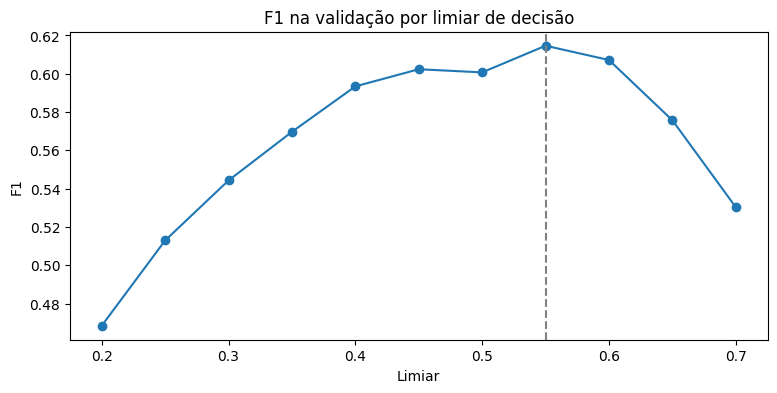

In [40]:
TECNICA = comparacao["F1"].idxmax()
modelo_escolhido = modelos[TECNICA]
probabilidades_valid = modelo_escolhido.predict_proba(features_valid)[:, 1]
limiares = np.arange(0.20, 0.71, 0.05)
f1_por_limiar = pd.Series([f1_score(target_valid, probabilidades_valid >= l) for l in limiares], index=limiares.round(2))
LIMIAR = f1_por_limiar.idxmax()
print(f"Técnica escolhida: {TECNICA}")
print(f"Melhor limiar: {LIMIAR} | F1 na validação: {f1_por_limiar.max():.3f} (com limiar 0,5: {f1_score(target_valid, probabilidades_valid >= 0.5):.3f})")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(f1_por_limiar.index, f1_por_limiar.values, marker="o")
ax.axvline(LIMIAR, color="gray", ls="--")
ax.set_title("F1 na validação por limiar de decisão")
ax.set_xlabel("Limiar")
ax.set_ylabel("F1")
plt.show()

## Valor de AUC-ROC

In [41]:
auc_roc = roc_auc_score(target_valid, probabilidades_valid)
print(f"AUC-ROC na validação: {auc_roc:.3f}")

AUC-ROC na validação: 0.854


## Aplicando o modelo no conjunto de teste

O conjunto de teste é usado **uma única vez**, com o modelo, a técnica de balanceamento e o limiar escolhidos na validação.

In [42]:
probabilidades_test = modelo_escolhido.predict_proba(features_test)[:, 1]
predictions_test = (probabilidades_test >= LIMIAR).astype(int)
print(f"F1 no teste: {f1_score(target_test, predictions_test):.3f} (meta: 0,59)")
print(f"AUC-ROC no teste: {roc_auc_score(target_test, probabilidades_test):.3f}")
print(f"Acurácia no teste: {accuracy_score(target_test, predictions_test):.3f}")
print()
print(classification_report(target_test, predictions_test))

F1 no teste: 0.597 (meta: 0,59)
AUC-ROC no teste: 0.852
Acurácia no teste: 0.840

              precision    recall  f1-score   support

           0       0.90      0.90      0.90      1593
           1       0.61      0.58      0.60       407

    accuracy                           0.84      2000
   macro avg       0.75      0.74      0.75      2000
weighted avg       0.84      0.84      0.84      2000



### Conclusões

No conjunto de teste, o modelo final alcançou **F1 de 0,60, acima da meta de 0,59**, com AUC-ROC de 0,85 e acurácia de 84%. Ele identifica 58% dos clientes que vão sair, com precisão de 61%.

[Voltar ao Índice](#back)

## Conclusão geral <a id='end'></a>

- **Correções desta versão:** na versão anterior, as técnicas de balanceamento eram avaliadas nos próprios dados de treino reamostrados, o que inflava os resultados, e o modelo final era treinado no conjunto de **validação**, com apenas 2 mil clientes. Agora, todas as escolhas são feitas pelo F1 na validação original, o modelo final é treinado no conjunto de treino e o teste é usado uma única vez.
- O modelo final é um **Random Forest** (profundidade 12, 50 árvores) treinado com **upsampling** da classe de clientes que saem e limiar de decisão de 0,55, escolhido na validação.
- Sem balanceamento, o F1 na validação era de 0,55, com recall de apenas 0,42. Com upsampling e o ajuste do limiar, chegou a 0,62.
- No teste, o modelo alcançou **F1 de 0,60, acima da meta de 0,59**, com AUC-ROC de 0,85 e acurácia de 84%.

**Próximos passos:** testar modelos de boosting, como LightGBM e CatBoost, e calcular o custo de cada erro (cliente que sai sem ser identificado contra ação de retenção desnecessária) para definir o limiar com base no negócio.